In [2]:
!pip install umap-learn

     ---------------------------------------- 0.0/57.4 kB ? eta -:--:--
     ---------------------------------------- 57.4/57.4 kB 1.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/91.8 kB ? eta -:--:--
   ---------------------------------------- 91.8/91.8 kB 2.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------ --------------------------------- 0.5/2.8 MB 10.0 MB/s eta 0:00:01
   ------------------------------- -------- 2.2/2.8 MB 28.4 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 25.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/73.5 kB ? eta -:--:--
   ---------------------------------------- 73.5/73.5 kB ? eta 0:00:00
   ---------------------------------------- 0.0/80.2 kB ? eta -:--:--
   ---------------------------------------- 80.2/80.2 kB 4.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   -- -----------------------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import f1_score, accuracy_score
from sklearn.decomposition import PCA
import umap

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')

# Cargar datos procesados
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').values.ravel()
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

# Escalador
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


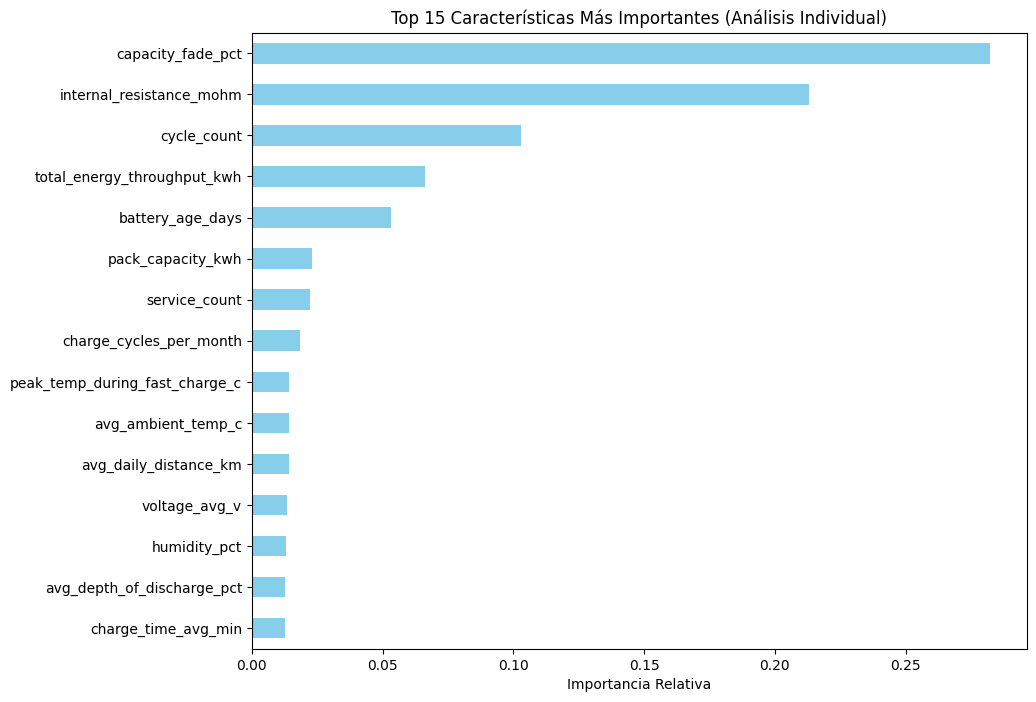

--- Candidatas a ser evaluadas/eliminadas (Menor importancia rel.): ---
vehicle_model_SUV-E5      0.001431
manufacturer_StormCell    0.001371
vehicle_model_Sedan-E1    0.001313
manufacturer_VoltaCore    0.001264
vehicle_model_Hatch-E3    0.001196
dtype: float64


In [4]:
# Importancia de características mediante Random Forest Baseline
rf_temp = RandomForestClassifier(n_estimators=200, random_state=42)
rf_temp.fit(X_train, y_train)

importances = pd.Series(rf_temp.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances.head(15).plot(kind='barh', color='skyblue')
plt.title('Top 15 Características Más Importantes (Análisis Individual)')
plt.xlabel('Importancia Relativa')
plt.gca().invert_yaxis()
plt.show()

print("--- Candidatas a ser evaluadas/eliminadas (Menor importancia rel.): ---")
print(importances.tail(5))

In [5]:
# Criterio: Retener el 90% de la varianza explicada acumulada
pca = PCA(n_components=0.90, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

n_comp_pca = pca.n_components_
pct_reduction_pca = (1 - (n_comp_pca / X_train.shape[1])) * 100

print(f"Número de componentes PCA seleccionados: {n_comp_pca} (de {X_train.shape[1]} originales)")
print(f"Porcentaje de reducción alcanzado: {pct_reduction_pca:.2f}%")

# Re-ajuste de hiperparámetros para Random Forest y SVM en espacio PCA
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_pca = []

# 1. Random Forest con PCA
grid_rf_pca = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    {'n_estimators': [100, 200], 'max_depth': [10, 20, None]},
    cv=cv_strategy, scoring='f1_macro', n_jobs=-1
).fit(X_train_pca, y_train)

y_pred_rf_pca = grid_rf_pca.best_estimator_.predict(X_test_pca)
f1_rf_pca = f1_score(y_test, y_pred_rf_pca, average='macro')

results_pca.append({
    'Técnica Reducción': 'PCA (Lineal)',
    'Modelo': 'Random Forest',
    'Componentes': n_comp_pca,
    '% Reducción': f"{pct_reduction_pca:.1f}%",
    'Test F1-Macro': round(f1_rf_pca, 4),
    'Test Accuracy': round(accuracy_score(y_test, y_pred_rf_pca), 4)
})

# 2. SVM con PCA
grid_svm_pca = GridSearchCV(
    SVC(class_weight='balanced', random_state=42),
    {'C': [0.1, 1.0, 10.0], 'kernel': ['rbf']},
    cv=cv_strategy, scoring='f1_macro', n_jobs=-1
).fit(X_train_pca, y_train)

y_pred_svm_pca = grid_svm_pca.best_estimator_.predict(X_test_pca)
f1_svm_pca = f1_score(y_test, y_pred_svm_pca, average='macro')

results_pca.append({
    'Técnica Reducción': 'PCA (Lineal)',
    'Modelo': 'SVM',
    'Componentes': n_comp_pca,
    '% Reducción': f"{pct_reduction_pca:.1f}%",
    'Test F1-Macro': round(f1_svm_pca, 4),
    'Test Accuracy': round(accuracy_score(y_test, y_pred_svm_pca), 4)
})

display(pd.DataFrame(results_pca))

Número de componentes PCA seleccionados: 30 (de 46 originales)
Porcentaje de reducción alcanzado: 34.78%


,Técnica Reducción,Modelo,Componentes,% Reducción,Test F1-Macro,Test Accuracy
0,PCA (Lineal),Random Forest,30,34.8%,0.8105,0.9332
1,PCA (Lineal),SVM,30,34.8%,0.7938,0.9239


In [6]:
# Proyección UMAP a N componentes (ej. 5 componentes)
n_comp_umap = 5
reducer = umap.UMAP(n_components=n_comp_umap, random_state=42, n_neighbors=15, min_dist=0.1)

X_train_umap = reducer.fit_transform(X_train_scaled)
X_test_umap = reducer.transform(X_test_scaled)

pct_reduction_umap = (1 - (n_comp_umap / X_train.shape[1])) * 100

results_umap = []

# 1. Random Forest con UMAP
grid_rf_umap = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    {'n_estimators': [100, 200], 'max_depth': [10, 20, None]},
    cv=cv_strategy, scoring='f1_macro', n_jobs=-1
).fit(X_train_umap, y_train)

y_pred_rf_umap = grid_rf_umap.best_estimator_.predict(X_test_umap)
f1_rf_umap = f1_score(y_test, y_pred_rf_umap, average='macro')

results_umap.append({
    'Técnica Reducción': 'UMAP (No Lineal)',
    'Modelo': 'Random Forest',
    'Componentes': n_comp_umap,
    '% Reducción': f"{pct_reduction_umap:.1f}%",
    'Test F1-Macro': round(f1_rf_umap, 4),
    'Test Accuracy': round(accuracy_score(y_test, y_pred_rf_umap), 4)
})

# 2. SVM con UMAP
grid_svm_umap = GridSearchCV(
    SVC(class_weight='balanced', random_state=42),
    {'C': [0.1, 1.0, 10.0], 'kernel': ['rbf']},
    cv=cv_strategy, scoring='f1_macro', n_jobs=-1
).fit(X_train_umap, y_train)

y_pred_svm_umap = grid_svm_umap.best_estimator_.predict(X_test_umap)
f1_svm_umap = f1_score(y_test, y_pred_svm_umap, average='macro')

results_umap.append({
    'Técnica Reducción': 'UMAP (No Lineal)',
    'Modelo': 'SVM',
    'Componentes': n_comp_umap,
    '% Reducción': f"{pct_reduction_umap:.1f}%",
    'Test F1-Macro': round(f1_svm_umap, 4),
    'Test Accuracy': round(accuracy_score(y_test, y_pred_svm_umap), 4)
})

# Unir y guardar todos los resultados comparativos
df_final_reduction = pd.DataFrame(results_pca + results_umap)
df_final_reduction.to_csv('../data/processed/dimensionality_reduction_results.csv', index=False)

display(df_final_reduction)

,Técnica Reducción,Modelo,Componentes,% Reducción,Test F1-Macro,Test Accuracy
0,PCA (Lineal),Random Forest,30,34.8%,0.8105,0.9332
1,PCA (Lineal),SVM,30,34.8%,0.7938,0.9239
2,UMAP (No Lineal),Random Forest,5,89.1%,0.6203,0.8909
3,UMAP (No Lineal),SVM,5,89.1%,0.3987,0.6130
